# Lab 4: Working with TABS Data
## to Understand Hurrican Ike on the Ocean
Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Add as many comments as you could when you solve the problem, which can help your remember what you have done.


***Submission***: For Python people, submit this Jupyter Notebook only

Name = "Noah Runions"

***Note:*** The functions/code provided are one of many ways that can work. Feel free to use functions you are more familiar with!\
***Figures:*** For any figures, label axis and title clearly for full points. 

## Lab Objectives:

1. Learn how to access and retrieve data from the Texas Automated Buoy System (TABS)
2. Import and analyze your data with Python
3. Plot wave velocity, speed, and water temperature data form a selected TABS buoy during Hurricane Ike (September 10–18, 2008)
4. Calculating basic statistics (mean, mode, median, std, max, min) and analyze correlations between two selected TABS buoys.

  
## Lab Activities: 
This lab has two parts, each worth 20 points, for a total of 40 points. Be sure to follow the instructions for both Part A and Part B.

In [1]:
import pandas as pd #data frame
import numpy as np  #matrix, numbers 
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import math
import seaborn as sns

## Part 4A (20 points). Analyzing TABS data during Hurricane Ike 2008

1. Download your data, and submit your txt files along with your notebook when you submit your assginments


2. Import the txt data into python
3. Change their name accordingly
4. Combine date and time into one column, make sure the format of time is correct

In [2]:
#your code to read the data, rename the columns, and change the date time

tabs = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab4\TABS_buoyD_sep2008.txt', sep=r'\s+')

tabs.columns = ['Date', 'Time','East', 'North', 'Speed', 'Dir', 'WaterTemp']

tabs['DateTime'] = pd.to_datetime(tabs['Date'] + ' ' + tabs['Time'])

5. Plot your data with 4 subplots:

- Subplot 1: Plotting “East” and “North” velocity time series
- Subplot 2: Plotting “Temperature” time series
- Subplot 3: Plotting “Speed” time series
- Subplot 4: Plotting histogram of “Speed” from 0 to 120 cm/s (bin size = 1)


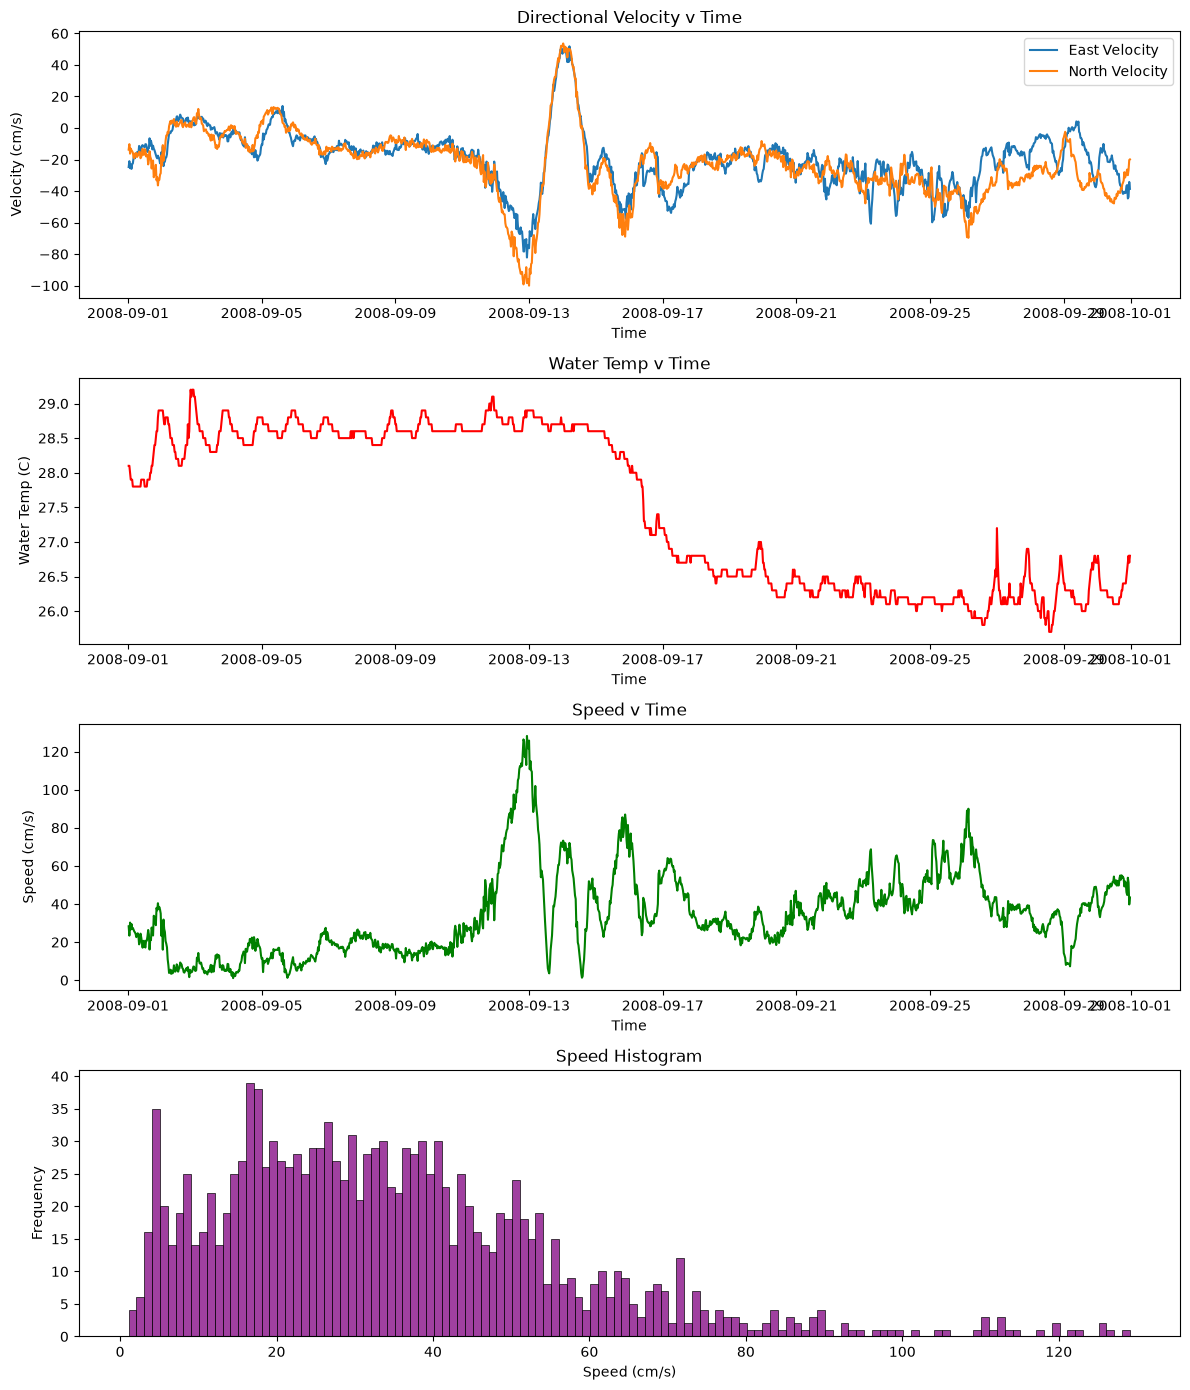

In [3]:
# Create figure with 4 subplots (4 rows, 1 column)
fig, axes = plt.subplots(4, 1, figsize=(12, 14))
#fig is your total figure
#axes are each subplot, this one will include 4, axes[0] to axes[3]
#depend on how many plots you wanna put, you need to change plt.subplots(row number, column number, figsize=(12, 14))

# Subplot 1: East and North velocity time series
sns.lineplot(data=tabs, x='DateTime', y='East', ax=axes[0], label='East Velocity')
sns.lineplot(data=tabs, x='DateTime', y='North',  ax=axes[0], label='North Velocity')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Velocity (cm/s)')
axes[0].set_title('Directional Velocity v Time')
axes[0].legend()

# Subplot 2: Temperature time series
sns.lineplot(data=tabs, x='DateTime', y='WaterTemp', ax=axes[1], color='red')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Water Temp (C)')
axes[1].set_title('Water Temp v Time')


# Subplot 3: Speed time series
sns.lineplot(data=tabs, x='DateTime', y='Speed', ax=axes[2], color='green')
axes[2].set_xlabel('Time')
axes[2].set_ylabel('Speed (cm/s)')
axes[2].set_title('Speed v Time')


# Subplot 4: Histogram of Speed (0 to 120 cm/s, bin size = 1)

bins = np.arange(min(tabs['Speed']), max(tabs['Speed']) + 1, 1)

sns.histplot(data=tabs, x='Speed', bins=bins, ax=axes[3], color='purple', kde=False)
axes[3].set_xlabel('Speed (cm/s)')
axes[3].set_ylabel('Frequency')
axes[3].set_title('Speed Histogram')


# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()


6.	Describe each plot here. For the histogram, please describe the shape and distribution of the data.\
Type your answer:

The directional velocities stay relatively consistant within +/- 20 cm/s about 0 with a large trought and peat around 9/13-9/15\
The water temp drops around 9/15-9/16, staying around 28.5 C before the drop and 26.5 C after\
The speed has a major spike on and after 9/13, and is consistantly below 40 cm/s before this but more varied after\
The speeed histogram shows a majority of the time the wind speeds were under 60 cm/s, with a large tail to the right of the data with very high windspeeds

7. Get a basic statistics using the df.describe function that we learnt

In [4]:
#your code
tabs.describe()

,East,North,Speed,Dir,WaterTemp,DateTime
count,1438.000000,1438.000000,1438.000000,1438.000000,1438.000000,1438
mean,-19.465577,-22.591801,34.575654,208.296453,27.502225,2008-09-16 00:00:55.076495
min,-82.160000,-100.010000,1.100000,4.400000,25.700000,2008-09-01 00:30:00
25%,-29.035000,-33.745000,18.445000,212.125000,26.300000,2008-09-08 12:07:30
50%,-17.635000,-21.690000,31.430000,220.300000,27.900000,2008-09-16 00:15:00
75%,-10.385000,-12.160000,45.827500,228.100000,28.600000,2008-09-23 11:52:30
max,51.830000,53.660000,128.200000,356.900000,29.200000,2008-09-30 23:30:00
std,18.450362,21.013064,21.807611,51.883209,1.132862,NaN


8. Describe the calculated statistics of each parameter\
Type your answer:

The east/north columns have similar numbers, with negative averages indicating a general southwestern current during this time\
The speed column is all positive, which makes since because the speed cannot be negative. It has a very high max compared to its average indicating high-speed outliers\
The water temp has the smalledt standard deviation and stays within 2 degrees of the mean\


9. Answer the questions:
- What is the fastest wave speed observed from your selected buoy?\
Type your answer:\
128.2 cm/s
- Is the wave speed distribution right-skewed or left-skewed?\
Type your answer:\
right-skewed


## Part 4B (20 points); Comparing TABS data between two buoys.
1. Download 60 days of data for two additional buoys between September 2015 and September 2016.
2. Submit your files along with your notebook
- Create the column names for each data, but use consistent names with the two

3. Import the data and create a figure with 3 subplots 
- Subplot 1: Wave speed time series for both buoys,
- Subplot 2: Histogram of the first buoy’s wave speed (bin size =1)
- Subplot 3: Histogram of the second buoy’s wave speed (bin size =1)


In [5]:
tabs_15 = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab4\TABS_buoyD_sep2015.txt', sep=r'\s+')

tabs_15.columns = ['Date', 'Time','East', 'North', 'Speed', 'Dir', 'WaterTemp']

tabs_15['DateTime'] = pd.to_datetime(tabs_15['Date'] + ' ' + tabs_15['Time'])

tabs_15['DateTimeNoYear'] = tabs_15['DateTime'].dt.strftime('%m-%d')


tabs_16 = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab4\TABS_buoyD_sep2016.txt', sep=r'\s+')

tabs_16.columns = ['Date', 'Time','East', 'North', 'Speed', 'Dir', 'WaterTemp']

tabs_16['DateTime'] = pd.to_datetime(tabs_16['Date'] + ' ' + tabs_16['Time'])

tabs_16['DateTimeNoYear'] = tabs_16['DateTime'].dt.strftime('%m-%d')

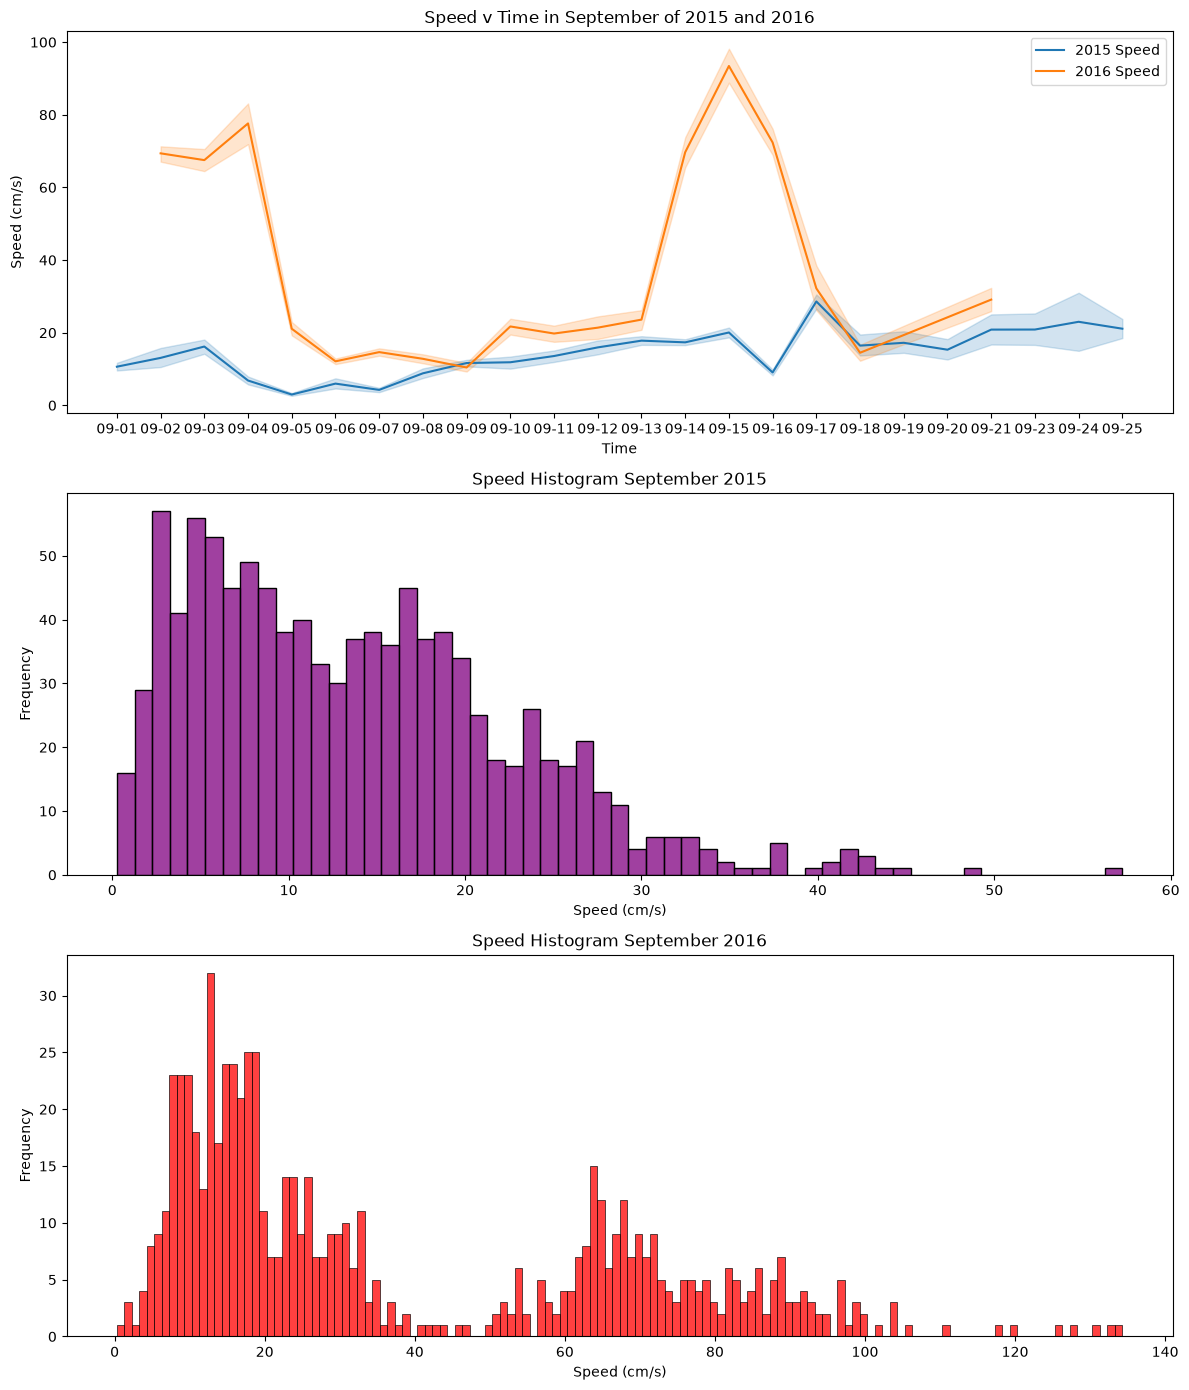

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14))

# Subplot 1: 2015 and 2016 speed time series
sns.lineplot(data=tabs_15, x='DateTimeNoYear', y='Speed', ax=axes[0], label='2015 Speed')
sns.lineplot(data=tabs_16, x='DateTimeNoYear', y='Speed',  ax=axes[0], label='2016 Speed')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Speed (cm/s)')
axes[0].set_title('Speed v Time in September of 2015 and 2016')
axes[0].legend()

# Subplot 2: Histogram of Speed 2015 (0 to 120 cm/s, bin size = 1)

bins = np.arange(min(tabs_15['Speed']), max(tabs_15['Speed']) + 1, 1)

sns.histplot(data=tabs_15, x='Speed', bins=bins, ax=axes[1], color='purple', kde=False)
axes[1].set_xlabel('Speed (cm/s)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Speed Histogram September 2015')

# Subplot 3: Histogram of Speed 2016 (0 to 120 cm/s, bin size = 1)

bins = np.arange(min(tabs_16['Speed']), max(tabs_16['Speed']) + 1, 1)

sns.histplot(data=tabs_16, x='Speed', bins=bins, ax=axes[2], color='red', kde=False)
axes[2].set_xlabel('Speed (cm/s)')
axes[2].set_ylabel('Frequency')
axes[2].set_title('Speed Histogram September 2016')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

4.	Describe the similarities and differences between the two buoys.\
Type your answer: 

Both were consistant around/under 20 cm/s, however the 2016 had higher spikes in wind speed than 2015\
Both histograms were clustered around/under 10 cm/s, however the 2016 histogram had much higher values and another cluster around 70 cm/s


5. Get a basic statistics using the df.describe function that we learnt


In [7]:
tabs_15.describe()

,East,North,Speed,Dir,WaterTemp,DateTime
count,1012.000000,1012.000000,1012.000000,1012.000000,1012.000000,1012
mean,-6.472292,-2.954783,13.667609,197.194763,29.656324,2015-09-11 21:22:13.992094
min,-56.410000,-42.870000,0.260000,0.000000,16.300000,2015-09-01 00:30:00
25%,-13.512500,-9.267500,6.275000,160.775000,28.900000,2015-09-06 06:52:30
50%,-5.580000,-4.170000,12.530000,222.600000,29.600000,2015-09-11 13:15:00
75%,0.850000,1.840000,19.022500,246.525000,29.900000,2015-09-17 06:37:30
max,25.430000,47.930000,56.700000,359.500000,46.400000,2015-09-25 15:30:00
std,9.814034,10.953781,8.943118,87.238632,3.407957,NaN


In [8]:
tabs_16.describe()

,East,North,Speed,Dir,WaterTemp,DateTime
count,711.000000,711.000000,711.000000,711.000000,711.000000,711
mean,-23.367876,-22.336203,37.850675,218.367089,30.418284,2016-09-11 03:42:26.835443
min,-113.450000,-81.000000,0.300000,11.600000,29.100000,2016-09-02 10:00:00
25%,-46.285000,-38.160000,13.810000,198.200000,30.200000,2016-09-07 14:45:00
50%,-14.870000,-14.850000,24.120000,225.300000,30.400000,2016-09-11 08:00:00
75%,-3.475000,-6.310000,65.105000,241.300000,30.700000,2016-09-15 01:45:00
max,32.850000,24.760000,133.690000,359.800000,32.000000,2016-09-21 19:00:00
std,26.231221,24.308521,29.844727,50.981398,0.484146,NaN


6. Calculate correlation 
- East velocity vs North velocity of every Buoy
- Temperature vs East velocity of every Buoy
- You should have 4 correlation relationships



In [9]:
print('2015 pearsonr East v North:')
en15 = pearsonr(tabs_15['East'], tabs_15['North'])
print('    Corelation :', en15.statistic)
print('       P-value :', en15.pvalue)
print()
print('2016 pearsonr East v North:')
en16 = pearsonr(tabs_16['East'], tabs_16['North'])
print('    Corelation :', en16.statistic)
print('       P-value :', en16.pvalue)
print()
print('2015 pearsonr Temp v East:')
te15 = pearsonr(tabs_15['WaterTemp'], tabs_15['East'])
print('    Corelation :', te15.statistic)
print('       P-value :', te15.pvalue)
print()
print('2016 pearsonr Temp v East:')
te16 = pearsonr(tabs_16['WaterTemp'], tabs_16['East'])
print('    Corelation :', te16.statistic)
print('       P-value :', te16.pvalue)

2015 pearsonr East v North:
    Corelation : 0.45889873509052403
       P-value : 7.494244477965497e-54

2016 pearsonr East v North:
    Corelation : 0.7189025726055724
       P-value : 4.320734202905256e-114

2015 pearsonr Temp v East:
    Corelation : 0.08115753895854864
       P-value : 0.009798787012657057

2016 pearsonr Temp v East:
    Corelation : 0.10308171634050917
       P-value : 0.005939067478233097


7.	Plot scatter plots for each pair and ensure the axes are correctly labeled. Use the subplot command so that the seven scatter plots are all on the same figure. \
Ensure all plots have appropriate and correct labeling.\
You should have 4 subplots


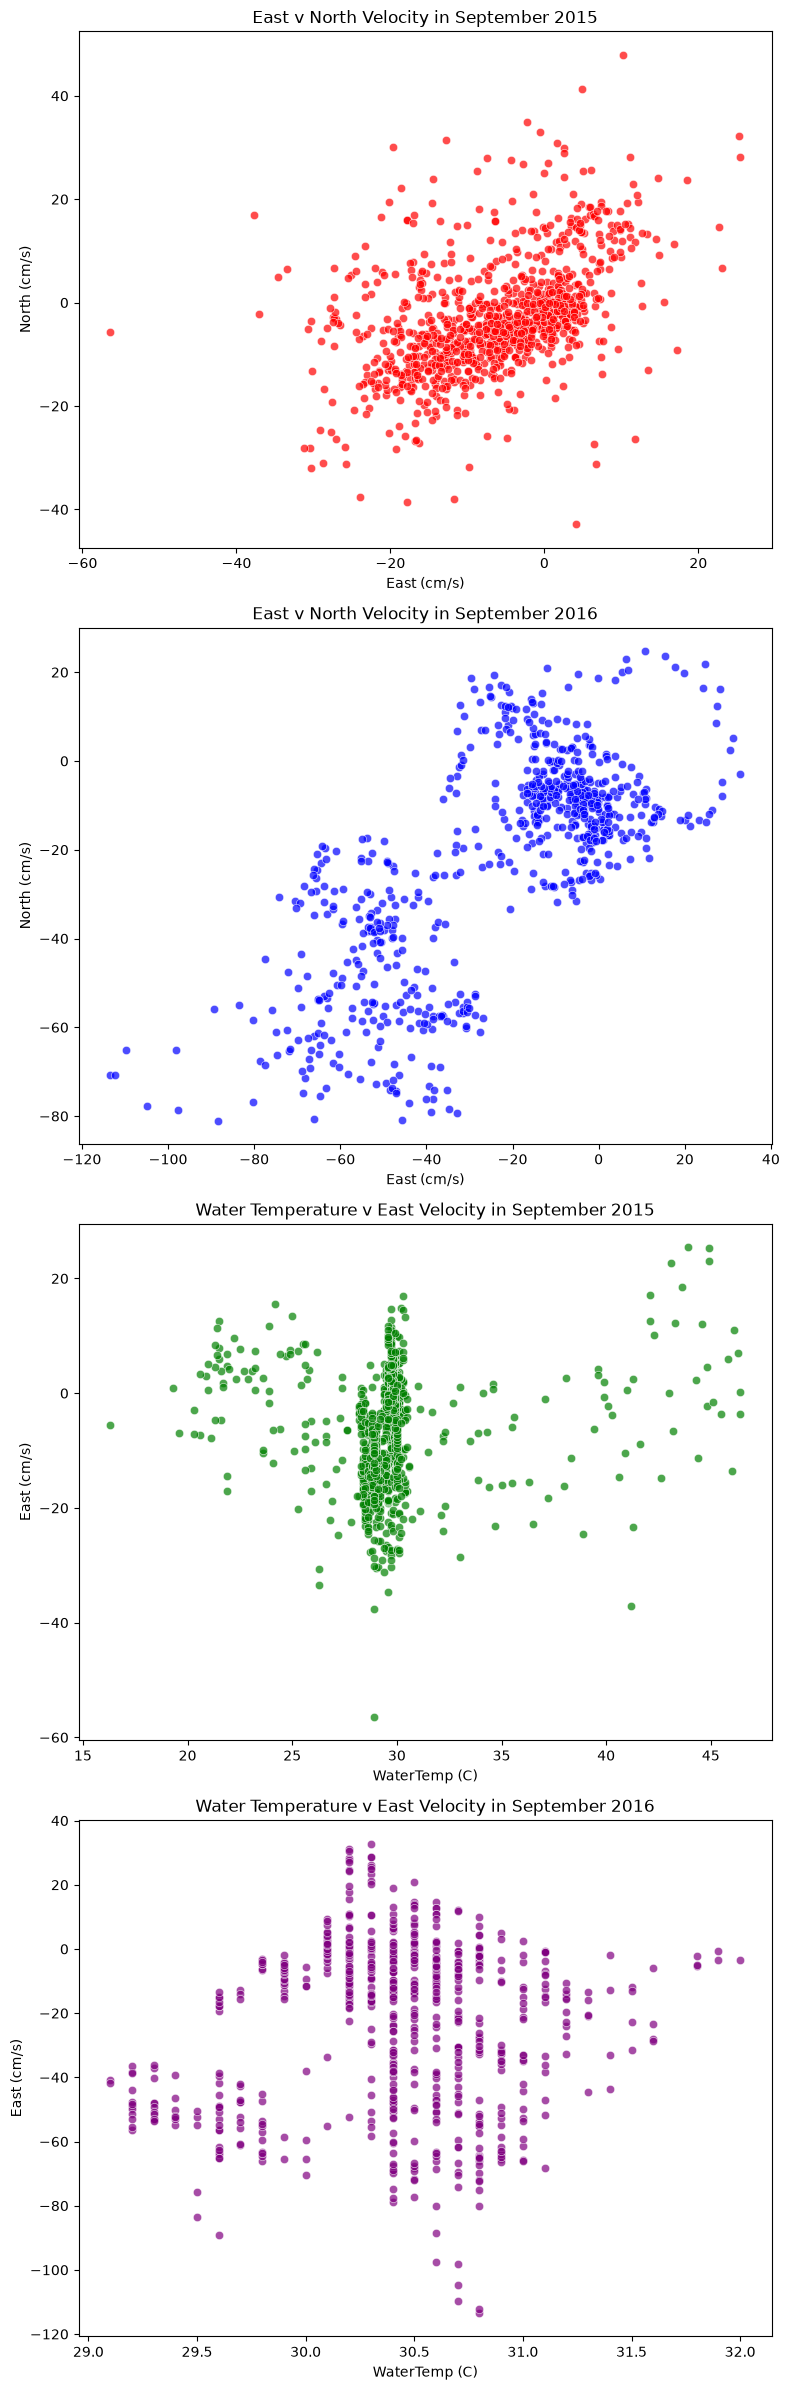

In [12]:
# Create figure with 4 subplots (4 rows, 1 column)
fig, axes = plt.subplots(4, 1, figsize=(8, 24))


# Subplot 1: East v North 2015
sns.scatterplot(data = tabs_15, x='East', y='North', ax=axes[0], color='r', alpha=0.7)
axes[0].set_xlabel("East (cm/s)")
axes[0].set_ylabel("North (cm/s)")
axes[0].set_title("East v North Velocity in September 2015")

# Subplot 2: East v North 2016
sns.scatterplot(data = tabs_16, x='East', y='North', ax=axes[1], color='b', alpha=0.7)
axes[1].set_xlabel("East (cm/s)")
axes[1].set_ylabel("North (cm/s)")
axes[1].set_title("East v North Velocity in September 2016")

# Subplot 3: Temp v East 2015
sns.scatterplot(data = tabs_15, x='WaterTemp', y='East', ax=axes[2], color='g', alpha=0.7)
axes[2].set_xlabel("WaterTemp (C)")
axes[2].set_ylabel("East (cm/s)")
axes[2].set_title("Water Temperature v East Velocity in September 2015")

# Subplot 3: Temp v East 2015
sns.scatterplot(data = tabs_16, x='WaterTemp', y='East', ax=axes[3], color='purple', alpha=0.7)
axes[3].set_xlabel("WaterTemp (C)")
axes[3].set_ylabel("East (cm/s)")
axes[3].set_title("Water Temperature v East Velocity in September 2016")


# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()
